# State of the art: structural, actuarial and rare-event portfolio models, and the open-source gap

**Question:** How far apart do the models of the literature put the capital of the same credit book, and is that spread larger or smaller than the uncertainty of the correlation every model takes as input?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 06 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- name the families of portfolio credit models in the literature the research found (structural, actuarial, the large-portfolio limit and its granularity adjustment, rare-event simulation) and say which of them Contraste runs and which it does not;
- compare five of them on one book with one calibration, in capital at 99% and 99.9%, and read the ratios the case reports as its impact figures;
- say what Gordy's result on the two families implies for the comparison, and how far this notebook goes in testing it;
- weigh the uncertainty of the correlation input against the choice of model, in capital;
- state the open-source gap the research found, with its date and its limits.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# The notebook sits three folders below the repository root
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


# Names of the validation lights
LIGHTS = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Seven committed files of case C10 (owner: this repository; the loss rates behind the fits come from the Federal Reserve's table `chgallsa`, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, public domain, licence class `mirror-allowed`):

- the five loan-type files in `data/derived/C10/`, each with the committed ladder of rungs C1 to C6 on the illustrative book of that loan type (a constructed book, never a bank's), the granularity block and the `impact` figures;
- `models-c10.json`: the definition of the ladder, the rungs with their engine function and reference, and the parameters of the case;
- `grid-22.json`: the simulator grid of notebook 06, from which we read the measured size of the correlation interval.

The simulations are rerun here at a tenth of the size of the full Monte Carlo runs of the case, which are the reference; the analytic rungs are computed in full. The next cell loads the files and prints the ladder as the case defines it.

In [2]:
# Load the files and print the ladder of the case with its engine functions
NAMES = {
    "commercial-industrial": "Commercial and industrial",
    "commercial-real-estate": "Commercial real estate",
    "residential": "Residential real estate",
    "credit-cards": "Credit cards",
    "other-consumer": "Other consumer",
}
read = lambda name: json.loads((ROOT / "data" / "derived" / "C10" / f"{name}.json").read_text(encoding="utf-8"))
docs = {k: read(k) for k in NAMES}
models = read("models-c10")
grid22 = read("grid-22")

print(f"{'rung':6s} {'method':30s} engine function")
for row in models["fit"]["ladder"]:
    print(f"{row['rung']:6s} {row['method']:30s} {row['engine_function'].replace('riskvalidation.', '')}")

rung   method                         engine function
C1     lhp-vasicek                    portfolio.portfolio.lhp_measures
C2     gaussian-copula-one-factor     portfolio.copula.simulate_gaussian
C2     gaussian-copula-multi-factor   portfolio.copula.simulate_gaussian
C3     student-t-copula               portfolio.copula.simulate_student_t
C4     creditrisk-plus                portfolio.creditrisk_plus.pmf_stable
C5     granularity-adjustment         portfolio.granularity.granularity_adjustment
C6     importance-sampling            portfolio.importance.importance_sample_gaussian
C6     importance-sampling            portfolio.importance.importance_sample_gaussian


## Method

The comparison is built so that the models differ in one thing, their structure, and nothing else. Every rung of the ladder takes **the same book** (three groups of identical names, 1,120 names, 100 million USD, LGD 45%), **the same PD and correlation** (the maximum-likelihood fit of notebook 02), and the same quantile levels. What each rung changes:

| Rung | Model | Change from the one above |
|---|---|---|
| C1 | large homogeneous portfolio | the closed-form limit: infinitely many names, one factor |
| C2 | Gaussian copula, one factor | the finite book, simulated |
| C2 | Gaussian copula, two sectors | two correlated sector factors instead of one |
| C3 | Student t copula, 5 degrees of freedom | tail dependence |
| C4 | CreditRisk+, stable recursion | an actuarial model with a Gamma factor, solved exactly |
| C5 | large-portfolio limit plus the granularity adjustment | the closed-form limit, corrected for concentration |
| C6 | importance sampling, Gaussian copula | the same model as C2, sampled to reach the tail |

Step 1 computes the three analytic rungs on the commercial book: C1, C4 and C5. Step 2 simulates the copula rungs, C2 and C3, and draws the loss tail of all of them. Step 3 repeats the two copula comparisons for the five loan types, to separate what belongs to the structure of the models from what belongs to the book. The State of the art section then sets the spread among the models against the uncertainty of the correlation. The first cell is Step 1.

In [3]:
# Compute the analytic rungs C1, C4 and C5 on the commercial book
from scipy import integrate, stats

from riskvalidation.engines.vasicek import conditional_pd
from riskvalidation.portfolio import creditrisk_plus as cr
from riskvalidation.portfolio import granularity as gr
from riskvalidation.portfolio import portfolio as pf
from riskvalidation.regulatory.irb import capital_requirement

ci = docs["commercial-industrial"]["outputs"]
book, groups, lgd = ci["portfolio"], ci["portfolio"]["groups"], ci["portfolio"]["lgd_mean"]
pd_hat, rho_hat = ci["fit"]["maximum_likelihood"]["pd"]["estimate"], ci["fit"]["maximum_likelihood"]["rho"]["estimate"]
rung = {r["id"]: r for r in ci["rungs"]}
levels = (0.99, 0.999)
c1 = pf.lhp_measures(book["total_ead"], lgd, pd_hat, rho_hat, levels)

loss_unit = next(p["value"] for p in rung["c4-creditrisk-plus"]["parameters"] if p["name"] == "loss_unit")
n_max = int(next(d["value"] for d in rung["c4-creditrisk-plus"]["diagnostics"] if d["name"] == "n_max"))
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in groups])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in groups])
density = lambda z: float(conditional_pd(pd_hat, rho_hat, z)) ** 2 * stats.norm.pdf(z)
second_moment, _ = integrate.quad(density, -12, 12, epsabs=1e-16, epsrel=1e-12, limit=200)
sigma2 = (second_moment - pd_hat ** 2) / pd_hat ** 2
inp = cr.CreditRiskPlusInput(
    nu=np.rint(ead * lgd / loss_unit).astype(int), pd=pd_names, w0=np.zeros(ead.size),
    weights=np.ones((ead.size, 1)), sigma2=np.array([sigma2]), loss_unit=loss_unit, currency=book["currency"])
pmf = cr.pmf_stable(inp, n_max)
c4 = cr.measures_from_pmf(pmf, loss_unit, levels)
print("sigma^2 =", round(sigma2, 6), "| C1 VaR 99.9%:", f"{c1[1].var:,.0f}", "| C4 VaR 99.9%:", f"{c4[1].var:,.0f}")

sigma^2 = 0.552066 | C1 VaR 99.9%: 2,298,833 | C4 VaR 99.9%: 3,078,000


The next cell computes the granularity adjustment of rung C5 from the IRB capital of each group, at 99% and 99.9%.

In [4]:
# Compute the granularity adjustment C5 from the IRB capital of each group
gran = ci["granularity"]
k_group = {}
for g in groups:
    k_group[g["id"]] = float(capital_requirement("corporate", g["pd"], lgd, regime="basel3", maturity=2.5).k)
k_names = np.concatenate([np.full(g["n_names"], k_group[g["id"]]) for g in groups])
share = ead / ead.sum()
lgd_names = np.full(ead.size, lgd)

ga_money = []
for level in levels:
    res = gr.granularity_adjustment(share, k_names, pd_names, lgd_names, gran["gamma"], gran["xi"], level)
    ga_money.append(res.ga * book["total_ead"])
    print(f"q = {level}: delta {res.delta:.4f} | GA {res.ga:.8f} | in money: {ga_money[-1]:,.0f}")
print("effective names of the book:", round(book["effective_names"], 1))

q = 0.99: delta 2.8568 | GA 0.00481771 | in money: 481,771
q = 0.999: delta 4.8336 | GA 0.00982976 | in money: 982,976
effective names of the book: 103.7


The three analytic rungs cost seconds and need no random numbers, which is why they are the reference for the simulated ones. The limit says the 99.9% VaR is a little over 2.3 million USD; CreditRisk+, which keeps the finite number of names, says about 3.1 million; the granularity adjustment closes most of that gap analytically by adding about 1 million to the limit. Step 2 now simulates the two copula rungs on the same book, with 100,000 scenarios each, and compares all of them in one table and one figure.

In [5]:
# Simulate the Gaussian copula with one and two factors and the Student t copula
from riskvalidation.portfolio import copula

one = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], one_factor=True)
el = pf.expected_loss(one)
chunk = rung["c2-gaussian-1f"]["simulation"]["chunk_size"]
rho_f = next(p["value"] for p in rung["c2-gaussian-mf"]["parameters"] if p["name"] == "factor_correlation")
factor_corr = np.array([[1.0, rho_f], [rho_f, 1.0]])
two = pf.portfolio_from_groups(groups, book["currency"], book["lgd_gamma"], factor_corr=factor_corr, one_factor=False)
nu = next(p["value"] for p in rung["c3-student-t"]["parameters"] if p["name"] == "nu")

seed = {k: rung[k]["simulation"]["seed"] for k in ("c2-gaussian-1f", "c2-gaussian-mf", "c3-student-t")}
sample = {
    "c2-gaussian-1f": copula.simulate_gaussian(one, 100_000, seed["c2-gaussian-1f"], chunk),
    "c2-gaussian-mf": copula.simulate_gaussian(two, 100_000, seed["c2-gaussian-mf"], chunk),
    "c3-student-t": copula.simulate_student_t(one, nu, 100_000, seed["c3-student-t"], chunk),
}
sim = {k: pf.measures_from_sample(s.losses, levels, el) for k, s in sample.items()}
for k, m in sim.items():
    print(f"{k:16s} VaR 99.9% {m[1].var:12,.0f} | error {m[1].var_se:9,.0f}")

c2-gaussian-1f   VaR 99.9%    3,087,000 | error    54,340
c2-gaussian-mf   VaR 99.9%    2,988,000 | error    35,076
c3-student-t     VaR 99.9%   13,815,000 | error   329,994


The next cell puts the six rungs in one table: VaR at 99% and 99.9%, the expected shortfall at 99.9% and the ratio of the 99.9% VaR to the large-portfolio limit.

In [6]:
# List the rungs at 99% and 99.9% with their ratio to the large-portfolio limit
labels = {
    "c2-gaussian-1f": "C2 Gaussian, 1 factor",
    "c2-gaussian-mf": "C2 Gaussian, 2 sectors",
    "c3-student-t": "C3 Student t",
}
ladder = {"C1 large portfolio": (c1[0].var, c1[0].es, c1[1].var, c1[1].es)}
for key, m in sim.items():
    ladder[labels[key]] = (m[0].var, m[0].es, m[1].var, m[1].es)
ladder["C4 CreditRisk+"] = (c4[0].var, c4[0].es, c4[1].var, c4[1].es)
ladder["C5 limit + GA"] = (c1[0].var + ga_money[0], None, c1[1].var + ga_money[1], None)
limit_999 = c1[1].var
print(f"{'rung':30s} {'VaR 99%':>11s} {'VaR 99.9%':>11s} {'ES 99.9%':>11s} {'ratio':>8s}")
for name, (var99, es99, var999, es999) in ladder.items():
    es_text = f"{es999:11,.0f}" if es999 is not None else f"{'-':>11s}"
    print(f"{name:30s} {var99:11,.0f} {var999:11,.0f} {es_text} {var999 / limit_999:8.3f}")

rung                               VaR 99%   VaR 99.9%    ES 99.9%    ratio
C1 large portfolio               1,500,956   2,298,833   2,680,019    1.000
C2 Gaussian, 1 factor            2,088,000   3,087,000   3,609,180    1.343
C2 Gaussian, 2 sectors           2,025,000   2,988,000   3,429,720    1.300
C3 Student t                     6,264,000  13,815,000  16,944,570    6.010
C4 CreditRisk+                   2,079,000   3,078,000   3,506,025    1.339
C5 limit + GA                    1,982,727   3,281,809           -    1.428


The next cell draws the probability of a larger loss for the exact rungs and the three simulated samples on one logarithmic axis.

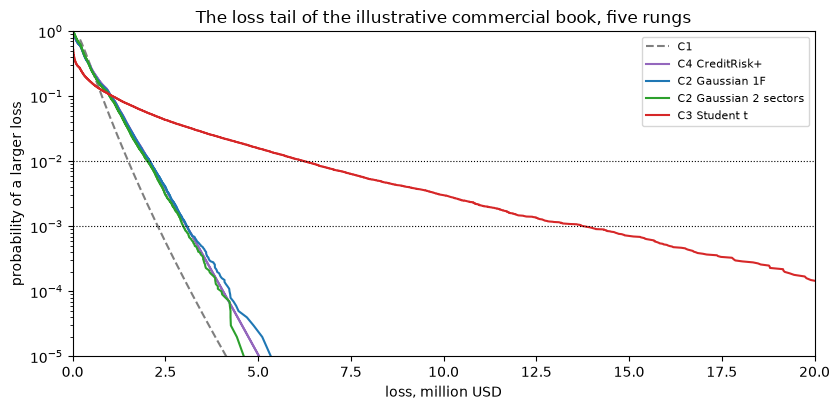

In [7]:
# Draw the loss tail of the rungs on one logarithmic axis
from riskvalidation.engines.vasicek import lhp_cdf

fig, ax = plt.subplots(figsize=(8.5, 4.2))
limit_loss = np.linspace(0.2, 20.0, 400) * 1e6
limit_exceed = 1 - lhp_cdf(limit_loss / (book["total_ead"] * lgd), pd_hat, rho_hat)
ax.plot(limit_loss / 1e6, limit_exceed, "--", color="tab:gray", label="C1")
ax.plot(np.arange(pmf.size) * loss_unit / 1e6, 1 - np.cumsum(pmf), color="tab:purple", label="C4 CreditRisk+")
styles = (
    ("c2-gaussian-1f", "tab:blue", "C2 Gaussian 1F"),
    ("c2-gaussian-mf", "tab:green", "C2 Gaussian 2 sectors"),
    ("c3-student-t", "tab:red", "C3 Student t"),
)
for key, color, label in styles:
    ordered = np.sort(sample[key].losses)
    exceed = 1.0 - np.arange(1, ordered.size + 1) / ordered.size
    ax.plot(ordered[:-1] / 1e6, exceed[:-1], color=color, label=label)
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="black", linestyle=":", linewidth=0.8)
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.set_xlim(0, 20)
ax.set_xlabel("loss, million USD")
ax.set_ylabel("probability of a larger loss")
ax.set_title("The loss tail of the illustrative commercial book, five rungs")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The grey dashed curve is the closed-form limit and it is the first to fall: with infinitely many names there is no lumpiness to produce large losses. The purple CreditRisk+ curve and the blue and green Gaussian copulas bunch together a little to the right of it, which is the cost of a book with 104 effective names and the answer the three finite-book models share. The red Student t curve leaves the others early and stays far to the right, reaching the 0.1% level at more than four times their loss. The figure draws the same marginal PD in every curve, so it isolates the structure of the dependence. It does not say which structure is true, and the comparison with the correlation uncertainty, below, puts the size of the gap in proportion.

Step 3 repeats the two copula comparisons on the five loan types. The books differ in size, concentration and fitted parameters, so the ratios show how much of the comparison belongs to the structure of the models and how much to the book. The next cell simulates the Gaussian and the Student t copula with 100,000 scenarios on the book of each loan type and prints the Student t over Gaussian ratio and the Gaussian over limit ratio at 99.9%.

In [8]:
# Simulate both copulas on the book of each loan type and form the two ratios at 99.9%
ratios = {}
print(f"{'loan type':26s} {'eff. names':>14s} {'t / Gauss.':>10s} {'Gauss. / limit':>14s}")
for key, label in NAMES.items():
    out_k = docs[key]["outputs"]
    book_k = out_k["portfolio"]
    fit_k = out_k["fit"]["maximum_likelihood"]
    rung_k = {r["id"]: r for r in out_k["rungs"]}
    one_k = pf.portfolio_from_groups(book_k["groups"], book_k["currency"], book_k["lgd_gamma"], one_factor=True)
    el_k = pf.expected_loss(one_k)
    chunk_k = rung_k["c2-gaussian-1f"]["simulation"]["chunk_size"]
    gauss = copula.simulate_gaussian(one_k, 100_000, rung_k["c2-gaussian-1f"]["simulation"]["seed"], chunk_k)
    student = copula.simulate_student_t(one_k, nu, 100_000, rung_k["c3-student-t"]["simulation"]["seed"], chunk_k)
    var_g = pf.measures_from_sample(gauss.losses, (0.999,), el_k)[0].var
    var_t = pf.measures_from_sample(student.losses, (0.999,), el_k)[0].var
    pd_k, rho_k = fit_k["pd"]["estimate"], fit_k["rho"]["estimate"]
    var_l = pf.lhp_measures(book_k["total_ead"], book_k["lgd_mean"], pd_k, rho_k, (0.999,))[0].var
    ratios[key] = (var_t / var_g, var_g / var_l)
    print(f"{label:26s} {book_k['effective_names']:14.0f} {var_t / var_g:10.2f} {var_g / var_l:14.2f}")

loan type                      eff. names t / Gauss. Gauss. / limit
Commercial and industrial             104       4.48           1.34
Commercial real estate                 50       2.71           1.17
Residential real estate               595      13.76           2.33
Credit cards                         1667       3.98           1.04
Other consumer                       1250       9.76           1.16


The next cell draws the two ratios for each loan type as grouped bars on a logarithmic axis.

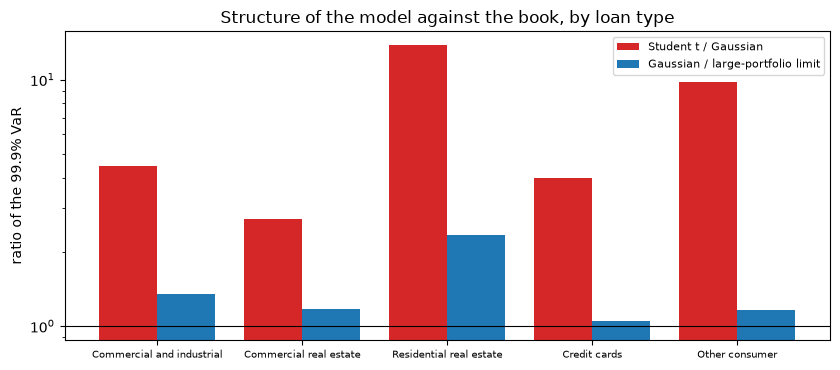

In [9]:
# Draw the two copula ratios of each loan type
position = np.arange(len(NAMES))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.bar(position - 0.2, [ratios[k][0] for k in NAMES], width=0.4, color="tab:red",
       label="Student t / Gaussian")
ax.bar(position + 0.2, [ratios[k][1] for k in NAMES], width=0.4, color="tab:blue",
       label="Gaussian / large-portfolio limit")
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_yscale("log")
ax.set_xticks(position, list(NAMES.values()), fontsize=7)
ax.set_ylabel("ratio of the 99.9% VaR")
ax.set_title("Structure of the model against the book, by loan type")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The red bars are always above one: the Student t copula asks for more capital than the Gaussian one on every book, as tail dependence says it must, but by very different factors, from about two and a half on the book with the fewest effective names to more than ten on the residential book. The blue bars are the concentration effect and also vary: they are close to one for credit cards and other consumer, whose books have over a thousand effective names, and largest where the book is lumpy. The ratios are therefore not constants of the models. They depend on the book and on its fitted PD and correlation, and a single number such as the 4.5 of the commercial book should never be quoted as the price of tail dependence in general. Each ratio rests on 100,000 scenarios, so the third digit is noise.

## State of the art

The research of this product (persisted dossier 04, section H) found the following state of practice for the loss distribution of a credit portfolio. Each line says what the source states, whether Contraste runs it, and what the dossier itself marks as unverified.

**Structural (threshold) models.**
- *CreditMetrics*, the J.P. Morgan technical document of 1997 reissued in 2007 (Gupton, Finger and Bhatia; https://www.msci.com/documents/10199/93396227-d449-4229-9143-24a94dab122f): asset-return thresholds from a rating's transition row, correlated asset returns that generate joint migrations, and revaluation at the horizon on the forward curve of the new rating, so losses are mark-to-market (migration mode) and not default-only. **Contraste does not run it.** The copulas of this topic are default-mode. The page-level formula references inside the document were not checked (UNVERIFIED), and the authors' names come from catalogue listings.
- *Gaussian copula* (Li, 2000, https://doi.org/10.3905/jfi.2000.319253): the copula framing of default correlation. **Run** (rung C2, notebook 03).
- *Student t copula* (Frey and McNeil, 2003, https://doi.org/10.21314/jor.2003.089; Demarta and McNeil, 2005, https://doi.org/10.1111/j.1751-5823.2005.tb00254.x): adds tail dependence. **Run** (rung C3, notebook 03), with 5 degrees of freedom as an assumption of the case, not an estimate.

**Actuarial model.**
- *CreditRisk+*, Credit Suisse First Boston (1997), the original document: **not accessed** by the research (its URL no longer resolves, UNVERIFIED primary). The model statement and the stable recursion are verified from Haaf, Reiss and Schoenmakers (2004, https://doi.org/10.21314/jor.2004.097; preprint read pp. 1 to 3). **Run** (rung C4, notebook 04); the original Panjer-type recursion is kept only as a shown comparison.

**The two families compared.**
- Gordy (2000, https://doi.org/10.1016/S0378-4266(99)00054-0) shows that CreditMetrics and CreditRisk+ can be mapped into each other's framework, and that differences come from distributional assumptions and parameters. The dossier records this from the abstract and the paper's well-known result, and its full text was not re-read (UNVERIFIED wording). This notebook does not test the equivalence: it only observes, on one book with a moment-matched Gamma factor, how close the two rungs come (Results).

**The large-portfolio limit and its granularity adjustment.**
- Vasicek's limit and the IRB formula rest on the asymptotic single risk factor result (Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8). The granularity adjustment that corrects the limit for concentration is Gordy and Lutkebohmert (2013, https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf), read directly by the research. **Run** (rung C5, notebook 04). Their exact adjustment (equation 14, with second-order terms) is not implemented; the simplified form (equation 17) is.

**Rare-event simulation.**
- Glasserman and Li (2005, https://doi.org/10.1287/mnsc.1050.0415): importance sampling for the normal copula, in two parts (conditional on the factors, and on the factors themselves). **Run** (rung C6, notebook 05) for the Gaussian copula. The dossier marks its transcription of the twist and of the mean shift as UNVERIFIED because the paper is paywalled, and the engine accepts nothing on trust: its acceptance is unbiasedness against plain Monte Carlo. The extension to heavy-tailed factors (Glasserman, Heidelberger and Shahabuddin, 2002, https://doi.org/10.1111/1467-9965.00141) specifies no twist for the Student t copula that the research could use, so **the Student t rung of the importance sampler did not run**, and the committed file records the reason and no number.

**Concentration beyond the name.**
- Sector concentration (Dullmann and Masschelein, 2007, https://doi.org/10.1007/s10693-007-0014-3, with the multi-factor adjustment of Pykhtin, 2004, whose bibliographic details are UNVERIFIED) and the supervisory overview of credit risk concentration (BCBS, 2006, https://www.bis.org/publ/bcbs_wp15.pdf, a search summary in the dossier) are **not run**. Contraste measures name concentration by the HHI and the granularity adjustment, and sector structure only through the two-sector copula of notebook 03.

**The open-source gap.**
- The dossier records, from a search dated 2026-10-04, that no maintained, permissively licensed Python implementation of CreditMetrics or CreditRisk+ was found: the CRAN packages CreditMetrics and crp.CSFP are archived, GCPM 1.2.2 (CRAN, 2016) is old and GPL-2, the Open Risk portfolioAnalytics repository (https://github.com/open-risk/portfolioAnalytics) is GPL-2.0, and small educational repositories exist (one in Julia, MIT). It is an absence finding bounded by that search and that date, and nothing here extends it. Contraste therefore ships its own engine under BSD-3-Clause and validates it against analytic anchors (the closed-form large-portfolio distribution, the IRB formula, the CreditRisk+ generating function and the granularity test vector 4.83).

The figure compares the models. One more comparison puts them in proportion: how much capital depends on the choice of model, and how much on the uncertainty of the correlation that every model takes as input. The next cell computes the large-portfolio 99.9% VaR at the ends of the 95% likelihood-ratio interval of the correlation from notebook 02, with the fitted PD, and sets that spread beside the spread among the models of Step 2. It also reads the measured size of the interval's estimator on the simulator, from `grid-22.json`, because an interval is only as useful as its coverage.

In [10]:
# Compare the spread of the 99.9% VaR over the correlation interval with the spread among the models
from riskvalidation.engines.vasicek import lhp_quantile

fit = ci["fit"]["maximum_likelihood"]
scale = book["total_ead"] * lgd
points = (("ci_low", fit["rho"]["ci_low"]), ("fit", fit["rho"]["estimate"]), ("ci_high", fit["rho"]["ci_high"]))
by_rho = {label: scale * float(lhp_quantile(0.999, pd_hat, value)) for label, value in points}
ends = {
    "ci_low": "lower end",
    "fit": "fit",
    "ci_high": "upper end",
}
print(f"{'rho':>8s} {'large-portfolio VaR 99.9%':>40s} {'ratio to the fit':>20s}")
for label, value in points:
    print(f"{value:8.4f} {by_rho[label]:40,.0f} {by_rho[label] / by_rho['fit']:20.3f}   ({ends[label]})")

models_999 = {name: values[2] for name, values in ladder.items()}
without_t = {k: v for k, v in models_999.items() if "Student" not in k}
print("high over low, correlation interval (same model):", round(by_rho["ci_high"] / by_rho["ci_low"], 2))
spread_five = max(without_t.values()) / min(without_t.values())
print("largest over smallest, five models without the t copula:", round(spread_five, 2))
print("largest over smallest, all six rungs:", round(max(models_999.values()) / min(models_999.values()), 2))
print("measured size of the maximum-likelihood interval test, 22 years:", grid22["impact"]["size_ml"]["value"])

     rho                large-portfolio VaR 99.9%     ratio to the fit
  0.0382                                1,645,635                0.716   (lower end)
  0.0637                                2,298,833                1.000   (fit)
  0.1158                                3,682,446                1.602   (upper end)
high over low, correlation interval (same model): 2.24
largest over smallest, five models without the t copula: 1.43
largest over smallest, all six rungs: 6.01
measured size of the maximum-likelihood interval test, 22 years: 0.0525


The next cell draws the 99.9% VaR at the three values of the correlation and under each of the six rungs on one axis.

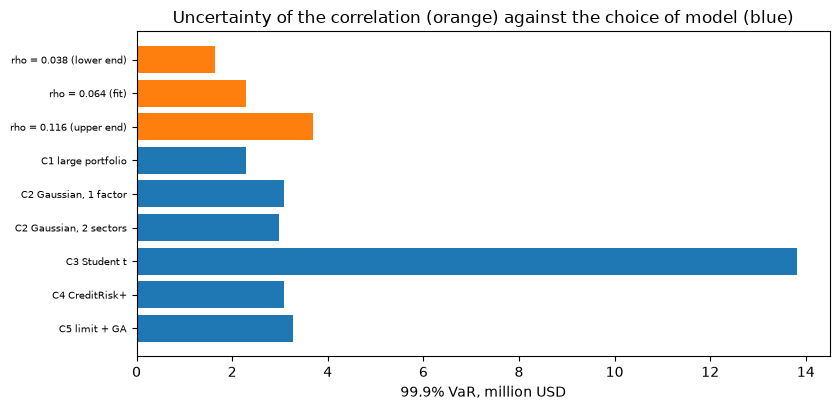

In [11]:
# Draw the 99.9% VaR for the correlation interval and for the six rungs
parameter_labels = [f"rho = {value:.3f} ({ends[label]})" for label, value in points]
names = parameter_labels + list(models_999)
values = [by_rho[label] for label, _ in points] + list(models_999.values())
colors = ["tab:orange"] * 3 + ["tab:blue"] * len(models_999)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.barh(range(len(names)), np.array(values) / 1e6, color=colors)
ax.set_yticks(range(len(names)), names, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("99.9% VaR, million USD")
ax.set_title("Uncertainty of the correlation (orange) against the choice of model (blue)")
fig.tight_layout()
plt.show()

The orange bars hold the model fixed and move only the correlation across its 95% interval; the blue bars hold the correlation fixed and change the model. The orange spread, from about 1.6 to 3.7 million USD, is wider than the spread among the five blue bars that exclude the Student t copula, which sit between 2.3 and 3.3 million, and narrower than the full blue range, which the Student t bar stretches to 13 million. Choosing among the finite-book models matters less than knowing the correlation, and assuming tail dependence matters more than either. The correlation interval was derived under independent years, which notebook 02 showed to be optimistic, so the orange spread is a lower bound.

## Results

**Answer:** on the 1,120-name commercial book the five analytic and Gaussian models put the 99.9% value at risk between 2,298,833 USD (the large-portfolio limit) and 3,281,809 USD (the limit plus the granularity adjustment), a spread of 1.43, while the Student t copula reaches 13,815,000 USD, 6.01 times the limit; moving the correlation across its 95% interval changes the large-portfolio VaR by a factor of 2.24, from 1,645,635 to 3,682,446 USD, so the correlation matters more than the choice among the five models and less than the assumption of tail dependence.

- **On one book, five models sit within 43% of each other and one does not.** At 99.9%, relative to the large-portfolio limit (2,298,833 USD), the two-sector Gaussian copula is 1.300, CreditRisk+ 1.339, the one-factor Gaussian copula 1.343 and the limit plus the granularity adjustment 1.428. The Student t copula is 6.010 times the limit, 13,815,000 USD, and its expected shortfall is 16,944,570 USD against 3,609,180 USD for the Gaussian copula. The tail-dependence assumption is the largest choice of structure in the ladder, larger than the whole spread among the other five models.
- **CreditRisk+ and the Gaussian copula land close together, as Gordy's result leads one to expect, and this is not a test of it.** CreditRisk+ gives 3,078,000 USD at 99.9% and the one-factor Gaussian copula 3,087,000 USD with a Monte Carlo error of 54,340 USD, so the two agree within the noise of the simulation. They share the PD and the variance of the default rate (the Gamma variance is matched by moments to the Vasicek default rate), so closeness is partly built in. The dossier records Gordy's statement from the abstract and marks its wording unverified, and this notebook compares one calibration of each family on one book.
- **Concentration costs the commercial book 982,976 USD at 99.9%.** The granularity adjustment of 0.00983 of exposure takes the large-portfolio VaR from 2,298,833 to 3,281,809 USD, 1.428 times, and the book has 103.7 effective names. The adjustment takes its capital from the IRB formula at the regulatory correlation while the limit uses the fitted one, so the ratio mixes concentration with the gap between the two correlations of notebook 02.
- **The structure of the model and the book are different things.** Across the five loan types the Student t copula asks for 2.71 to 13.76 times the Gaussian VaR at 99.9% (2.71 for commercial real estate, 4.48 for commercial and industrial, 13.76 for residential) and the finite book sits 1.04 to 2.33 times above its limit. Each ratio rests on 100,000 scenarios. The ratios depend on the fitted PD and correlation of each book, so the 4.48 of the commercial book is not a general price of tail dependence.
- **The correlation input matters more than the choice among the five models, and less than the tail dependence.** The large-portfolio 99.9% VaR at the ends of the 95% likelihood-ratio interval of the correlation is 1,645,635 and 3,682,446 USD, 0.716 and 1.602 times the fit, a spread of 2.24 from one end to the other with the model held fixed. Among the five models without the t copula the spread is 1.43; with the t copula it is 6.01. The estimator behind the interval has a measured size of 0.0525 against 0.05 on the simulator at 22 years, so the interval is honest on independent years, and notebook 02 showed that real years are strongly autocorrelated.
- **The open-source gap, with its limits.** The dossier found no maintained, permissively licensed Python implementation of CreditMetrics or CreditRisk+ in a search dated 2026-10-04. That is an absence finding bounded by one search, and this notebook cannot widen it. What the notebook shows is the other side: a permissively licensed engine whose analytic rungs run in seconds and whose Monte Carlo rungs agree with them within their standard errors (notebooks 03 to 05).

What this notebook does not show: CreditMetrics in migration mode (not implemented), the sector-concentration models of the literature (not run), heavy-tailed importance sampling (the research found no twist to implement), or which of the models a bank should adopt. The comparison is default-mode on illustrative books.

## Summary

- The literature the research found has structural models (CreditMetrics, Gaussian and t copulas), the actuarial CreditRisk+, the large-portfolio limit with its granularity adjustment and rare-event simulation; Contraste runs all of them except the migration mode of CreditMetrics, and it records that the Student t importance sampler did not run.
- On one book and one calibration, five models sit within 43% of each other at 99.9%, and the Student t copula is 6.0 times the limit: tail dependence is the largest structural choice.
- CreditRisk+ and the Gaussian copula agree within the Monte Carlo noise on the commercial book, partly by construction; this is consistent with Gordy's equivalence and is not a test of it.
- The correlation input moves capital by a factor of 2.2 across its 95% interval, more than the choice among the five models, and the interval's size is 0.0525 on independent years.
- The ratios between models depend on the book: the Student t copula asks for 2.7 to 13.8 times the Gaussian capital across the five loan types.
- The open-source gap is an absence finding from a search dated 2026-10-04; Contraste answers it with a permissively licensed engine checked against analytic anchors.

**What to try next.** Recompute the parameter spread for credit cards or residential from their own intervals and compare it with their model spread. Then open notebook 08 for the claim this topic demonstrates.

## References

- Gordy, M. B. (2000), A comparative anatomy of credit risk models, Journal of Banking and Finance 24(1-2):119-149. https://doi.org/10.1016/S0378-4266(99)00054-0
- Gupton, G. M., Finger, C. C. and Bhatia, M. (1997), CreditMetrics Technical Document, J.P. Morgan, reissued by RiskMetrics Group (2007) and hosted by MSCI (authors as usually cited). https://www.msci.com/documents/10199/93396227-d449-4229-9143-24a94dab122f
- Li, D. X. (2000), On default correlation: a copula function approach, Journal of Fixed Income 9(4):43-54. https://doi.org/10.3905/jfi.2000.319253
- Frey, R. and McNeil, A. J. (2003), Dependent defaults in models of portfolio credit risk, Journal of Risk 6(1):59-92. https://doi.org/10.21314/jor.2003.089
- Demarta, S. and McNeil, A. J. (2005), The t copula and related copulas, International Statistical Review 73(1):111-129. https://doi.org/10.1111/j.1751-5823.2005.tb00254.x
- Haaf, H., Reiss, O. and Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. and Lutkebohmert, E. (2013), Granularity adjustment for regulatory capital assessment, International Journal of Central Banking 9(3):33-48. https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf
- Glasserman, P. and Li, J. (2005), Importance sampling for portfolio credit risk, Management Science 51(11):1643-1656. https://doi.org/10.1287/mnsc.1050.0415
- Glasserman, P., Heidelberger, P. and Shahabuddin, P. (2002), Portfolio value-at-risk with heavy-tailed risk factors, Mathematical Finance 12(3):239-269. https://doi.org/10.1111/1467-9965.00141
- BCBS (2006), Studies on credit risk concentration: an overview of the issues and a synopsis of the results from the Research Task Force project, Working Paper No. 15. https://www.bis.org/publ/bcbs_wp15.pdf
- Dullmann, K. and Masschelein, N. (2007), A tractable model to measure sector concentration risk in credit portfolios, Journal of Financial Services Research 32(1-2):55-79. https://doi.org/10.1007/s10693-007-0014-3
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- Credit Suisse First Boston (1997), CreditRisk+: A Credit Risk Management Framework: not accessed by the research (UNVERIFIED primary).
- Pykhtin, M. (2004), Multi-factor adjustment, Risk 17(3): bibliographic details not verified by the research (UNVERIFIED).
- Persisted research dossier 04 of this product (credit-risk models, state of the art), section H, in particular H.3 to H.8; the open-source search is dated 2026-10-04.
- Open Risk portfolioAnalytics (GPL-2.0), https://github.com/open-risk/portfolioAnalytics, named by the dossier among the implementations found.